
---
date: "2026-11-13"
date-modified: last-modified
format:
  html:
    toc: true
---


# Hawkes Processes in Market Microstructure

**Prerequisites:** [Multivariate Hawkes processes](multivariate-hawkes-processes.ipynb) · [Estimating Hawkes processes](hawkes-estimation.ipynb) · [Stochastic models in finance](stochastic-models-in-finance.ipynb#def-marked-point-process)

At the scale of milliseconds to minutes, a market is a stream of discrete events: orders arrive, are cancelled or executed, and the price moves by whole ticks. Hawkes processes are the standard first model of this event flow. This note collects the extensions that microstructure models use (time-varying baselines, marks, inhibition, cross-excitation between event types), proves the signature-plot formula of the simplest Hawkes price model, describes what is known about criticality, and briefly surveys the other generalizations in the literature.

## 1\. Event Streams in a Limit Order Book

A **limit order book** lists the outstanding buy orders (bids) and sell orders (asks) at each price level. The events that change it are:

- **market orders**, which execute immediately against the best opposite quote (buyer- or seller-initiated trades);
- **limit orders**, which add volume at some price level;
- **cancellations**, which remove previously posted volume;
- as a consequence, **mid-price changes** up or down by a tick.

Each event type, possibly split by side and by price level, is a component of a multivariate point process, and each event carries marks (volume, price level, side). Empirically, all these streams are strongly clustered, they excite each other (a large market order is followed by more market orders on the same side, by cancellations and by new limit orders refilling the book), and their intensity has a strong intraday pattern. Fitted Hawkes models typically find branching ratios close to $1$ and kernels that decay slowly, close to power laws over several time scales. The precise numbers depend on the asset, the period and the method; the qualitative picture is robust.

## 2\. Time-Varying Baselines

::: {#def-hawkes-varying-baseline}
## Hawkes process with a time-varying baseline
For a locally integrable $\mu(t) \ge 0$, the intensity is $\lambda_t = \mu(t) + \sum_{T_i < t}\varphi(t - T_i)$. The cluster representation holds with immigrants forming an inhomogeneous Poisson process with rate $\mu(t)$, and the likelihood is as in [the estimation note](hawkes-estimation.ipynb#prp-hawkes-loglik) with $\mu T$ replaced by $\int_0^T\mu(t)\,dt$.
:::

::: {.callout-warning}
## Seasonality masquerades as excitation
A deterministic intraday pattern makes events cluster in busy periods even without any excitation. A Hawkes model with a constant baseline can only explain this clustering through the kernel, so it overestimates $\eta$. Always model or remove the intraday profile (for example with $\mu(t) = c\,s(t)$, $s$ an estimated daily profile) before interpreting the branching ratio. The simulation in §8 shows the effect on Poisson data.
:::

## 3\. Marked Hawkes Processes

::: {#def-marked-hawkes}
## Marked Hawkes process
Each event $T_i$ carries a mark $M_i$ in a mark space $\mathcal{M}$ (volume, side, price level, earthquake magnitude). The process is described by a ground intensity and a conditional mark density:
$$
\lambda(t, m) = \lambda_g(t)\,f(m \mid t), \qquad \lambda_g(t) = \mu + \sum_{T_i < t}\psi(M_i)\,\varphi(t - T_i),
$$
where $\psi \ge 0$ is the **impact function** of the mark. The marks are **unpredictable** if $f(m \mid t) = f(m)$ does not depend on the past: they are i.i.d. with density $f$, but they still influence the future through $\psi$. The likelihood of $(t_1, m_1), \dots, (t_n, m_n)$ on $[0, T]$ is
$$
L = \Big[\prod_i\lambda_g(t_i)\,f(m_i \mid t_i)\Big]\exp\Big(-\int_0^T\lambda_g(t)\,dt\Big).
$$
:::

::: {#prp-marked-branching-ratio}
## Branching ratio with unpredictable marks
With i.i.d. marks of density $f$, the ground process has the cluster structure of a Hawkes process in which an event with mark $m$ has $\operatorname{Pois}(\psi(m)\|\varphi\|_1)$ children, and the effective branching ratio is
$$
\eta = E[\psi(M)]\,\|\varphi\|_1 .
$$
If $\eta < 1$ the stationary mean intensity is $\mu/(1 - \eta)$.
:::

::: {.callout-tip collapse="true"}
## Proof of @prp-marked-branching-ratio
The cluster construction applies with the marks attached: an event at $s$ with mark $m$ has children forming an inhomogeneous Poisson process with rate $\psi(m)\varphi(\cdot - s)$, whose total mass is $\psi(m)\|\varphi\|_1$; the children's marks are drawn independently from $f$. The number of children of a typical event is therefore Poisson given its mark, with mean $E[\psi(M)]\|\varphi\|_1 = \eta$ after averaging over the independent mark. Generation sizes satisfy $E\,Z_k = \eta^k$ exactly as in the [branching structure](hawkes-process.ipynb#prp-branching-structure), and the mean-intensity computation of the [mean theorem](hawkes-process.ipynb#thm-hawkes-mean) goes through with $\varphi$ replaced by $E[\psi(M)]\varphi$: $m = \mu + E[\psi(M)]\,\varphi * m$, because the mark of each past event is independent of its time. $\blacksquare$
:::

A common choice in finance is $\psi(v) = (v/\bar v)^{\gamma}$ for the traded volume $v$, normalized so that $E\,\psi(M) = 1$: larger trades trigger more activity. The best-known marked model outside finance is the **ETAS model** of seismology, where the mark is the earthquake magnitude, marks follow the Gutenberg–Richter law $f(m) = b\,e^{-b(m - m_0)}$, the impact is exponential in the magnitude, $\psi(m) = A e^{a(m - m_0)}$ (Utsu's productivity law), and the kernel is the Omori–Utsu power law $\varphi(t) \propto (1 + t/c)^{-p}$.

## 4\. Nonlinear Hawkes Processes and Inhibition

::: {#def-nonlinear-hawkes}
## Nonlinear Hawkes process
Let $h : [0, \infty) \to \mathbb{R}$ (possibly negative) and $\Psi : \mathbb{R} \to [0, \infty)$. A **nonlinear Hawkes process** has intensity
$$
\lambda_t = \Psi\Big(\mu + \sum_{T_i < t}h(t - T_i)\Big).
$$
The linear Hawkes process is $\Psi(x) = x$ with $h = \varphi \ge 0$. Common choices are $\Psi(x) = \max(x, 0)$ and $\Psi(x) = e^x$.
:::

With $h < 0$ an event *lowers* the intensity: **self-inhibition**, which makes events more regular than Poisson (a refractory period). In order books, inhibition appears for instance between events that deplete and events that replenish a queue.

::: {#thm-nonlinear-stability}
## Stability of nonlinear Hawkes processes
If $\Psi$ is $L$-Lipschitz and $L\int_0^\infty|h(t)|\,dt < 1$, there is a unique stationary nonlinear Hawkes process with these parameters. (Stated without proof.)
:::

Simulation is by [thinning](hawkes-simulation.ipynb#thm-ogata-thinning) with a bound such as $\Psi\big(\mu + \sum h^+(t - T_i)\big)$ for nondecreasing $\Psi$; with purely inhibitory $h \le 0$ and $\Psi(x) = \max(x, 0)$, the constant $\mu$ is a valid bound.

## 5\. A Hawkes Model of the Price

The simplest Hawkes model of the price counts upward and downward tick moves. Let $N^+$ and $N^-$ count the up and down moves, and let the (tick) price be
$$
X_t = X_0 + N^+_t - N^-_t .
$$
Prices at high frequency are **mean-reverting**: an up-move makes a down-move more likely soon after (bid–ask bounce, discreteness of the tick grid). The model encodes this by cross-excitation only.

::: {#def-hawkes-price-model}
## Bivariate Hawkes price model
$(N^+, N^-)$ is a bivariate Hawkes process with equal baselines $\mu$ and kernels
$$
\varphi_{++} = \varphi_{--} = 0, \qquad \varphi_{+-} = \varphi_{-+} = \varphi, \qquad \varphi(t) = \alpha e^{-\beta t},\quad \eta = \alpha/\beta < 1 .
$$
:::

The total number of moves $S = N^+ + N^-$ is then a univariate Hawkes process with kernel $\varphi$ (every move raises the total intensity by $\alpha$), so each side has stationary mean intensity $\bar\lambda = \mu/(1 - \eta)$. The **signature plot** is the realized variance per unit time when the price is sampled every $\tau$:
$$
C(\tau) = \frac{1}{\tau}\operatorname{Var}\big(X_{t+\tau} - X_t\big).
$$
For a Brownian price $C$ is constant; for real prices $C(\tau)$ decreases as $\tau$ grows over the first seconds to minutes, which is the signature of microstructure noise.

::: {#thm-signature-plot}
## Signature plot of the Hawkes price model
In the stationary regime of @def-hawkes-price-model, with $\gamma = \alpha + \beta$,
$$
C(\tau) = 2\bar\lambda\Big[\frac{1}{(1 + \eta)^2} + \Big(1 - \frac{1}{(1+\eta)^2}\Big)\frac{1 - e^{-\gamma\tau}}{\gamma\tau}\Big].
$$
In particular $C$ decreases from $C(0^+) = 2\bar\lambda$ to the macroscopic variance per unit time $C(\infty) = 2\bar\lambda/(1 + \eta)^2$.
:::

::: {.callout-tip collapse="true"}
## Proof of @thm-signature-plot
Write $\lambda^\pm$ for the two intensities, $Y = \lambda^+ - \lambda^-$ and $\Sigma = \lambda^+ + \lambda^-$; in the stationary regime $E\,Y = 0$ and $E\,\Sigma = 2\bar\lambda$. An up-move raises $\lambda^-$ by $\alpha$ and a down-move raises $\lambda^+$ by $\alpha$, and between moves both excesses decay at rate $\beta$; hence $Y$ decays at rate $\beta$, jumps by $-\alpha$ at up-moves and by $+\alpha$ at down-moves. The proof of [Dynkin's formula](hawkes-process.ipynb#lem-dynkin-hawkes) applies verbatim to this Markov process: for a function $f(x, y)$ of the price increment $x = X_s - X_a$ and of $Y_s$,
$$
\frac{d}{ds}E\,f = E\big[-\beta Y\,\partial_yf + \lambda^+\big(f(x + 1, y - \alpha) - f\big) + \lambda^-\big(f(x - 1, y + \alpha) - f\big)\big].
$$

*Variance of $Y$.* With $f = y^2$: $\lambda^+((y - \alpha)^2 - y^2) + \lambda^-((y + \alpha)^2 - y^2) = -2\alpha yY + \alpha^2\Sigma$, so $\frac{d}{ds}E Y^2 = -2(\alpha + \beta)E Y^2 + 2\alpha^2\bar\lambda$, and in stationarity $E Y^2 = \alpha^2\bar\lambda/\gamma$.

*Covariance of the increment with $Y$.* With $f = xy$: the jump terms give $\lambda^+((x + 1)(y - \alpha) - xy) + \lambda^-((x - 1)(y + \alpha) - xy) = y\,Y - \alpha x\,Y - \alpha\Sigma$. Since $y = Y$, $C_1(s) := E[(X_s - X_a)Y_s]$ satisfies $C_1' = -\gamma C_1 + E Y^2 - 2\alpha\bar\lambda$, $C_1(a) = 0$, so
$$
C_1(s) = \frac{c_1}{\gamma}\big(1 - e^{-\gamma(s - a)}\big), \qquad c_1 = \frac{\alpha^2\bar\lambda}{\gamma} - 2\alpha\bar\lambda = -\frac{\alpha\bar\lambda(\alpha + 2\beta)}{\gamma}.
$$

*Variance of the increment.* With $f = x^2$: $\lambda^+(2x + 1) + \lambda^-(1 - 2x) = 2xY + \Sigma$, so $\frac{d}{ds}E(X_s - X_a)^2 = 2C_1(s) + 2\bar\lambda$ and
$$
\operatorname{Var}(X_{a+\tau} - X_a) = 2\bar\lambda\tau + \frac{2c_1}{\gamma}\Big(\tau - \frac{1 - e^{-\gamma\tau}}{\gamma}\Big).
$$
Divide by $\tau$. The constant term is $2\bar\lambda + 2c_1/\gamma = 2\bar\lambda\big(1 - \alpha(\alpha + 2\beta)/\gamma^2\big) = 2\bar\lambda\beta^2/\gamma^2 = 2\bar\lambda/(1 + \eta)^2$, and the coefficient of $(1 - e^{-\gamma\tau})/(\gamma\tau)$ is $-2c_1/\gamma = 2\bar\lambda\alpha(\alpha + 2\beta)/\gamma^2 = 2\bar\lambda\big(1 - 1/(1 + \eta)^2\big)$. $\blacksquare$
:::

::: {.callout-note}
## Intuition: why high-frequency variance is too large
Over a very short interval the price moves at rate $2\bar\lambda$ with independent-looking ticks, so $C(0^+) = 2\bar\lambda$. But every move raises the chance of a move back: over long horizons a fraction of the moves cancel, and the variance per unit time drops by the factor $(1 + \eta)^2$. Realized variance computed from tick data therefore overestimates the variance relevant at daily scales, unless sampling is sparse or the estimator is corrected. With self-excitation added ($\varphi_{++} = \varphi_{--} \ne 0$) the same model also produces trending behaviour; a four-dimensional version with two assets reproduces the **Epps effect** (correlations measured at high frequency are smaller than at low frequency).
:::

## 6\. Criticality and Long Memory

When Hawkes models are fitted to long samples of financial event data, the estimated branching ratio is often close to $1$, especially with power-law kernels; with exponential kernels and constant baselines the estimates are lower but drift upward over the years. Two cautions from the previous notes apply: seasonal baselines and regime shifts inflate $\hat\eta$ (§2), and near $\eta = 1$ the likelihood is flat ([practical difficulties](hawkes-estimation.ipynb#thm-hawkes-mle-asymptotics)). Taking the empirical picture at face value, markets operate near the critical regime: most activity is endogenous, triggered by earlier activity rather than by news.

This regime has a precise mathematical meaning. Consider a sequence of Hawkes processes on $[0, T]$ with branching ratios $\eta_T \to 1$ such that $T(1 - \eta_T)$ converges, and rescale time by $T$ and counts by $T^2$ or so. Then (stated without proof):

1. with an integrable kernel of finite mean, the rescaled intensity converges to a **square-root (CIR) diffusion**;
2. with a heavy-tailed kernel $\varphi(t) \sim t^{-1-a}$, $\tfrac12 < a < 1$, the limit is a **rough** (fractional) square-root process.

Through the link between order flow and price variance, the second result gives a microstructural foundation for **rough volatility** models, in which volatility behaves like a fractional process with Hurst exponent well below $\tfrac12$. This is one of the main reasons Hawkes processes are central in modern quantitative finance.

## 7\. Other Generalizations

The literature extends almost every ingredient of the [definition of the Hawkes process](hawkes-process.ipynb#def-hawkes-process). Short descriptions, for orientation:

- **Spatio-temporal processes.** Events have locations $s_i \in \mathbb{R}^2$; $\lambda(t, s) = \mu(s) + \sum_{T_i < t}\varphi(t - T_i)\,g(s - s_i)$. The space-time ETAS model of seismology is the main example; its fitting alternates between estimating the background $\mu(s)$ and **stochastic declustering** with the [branching probabilities](hawkes-estimation.ipynb#prp-complete-likelihood).
- **Renewal Hawkes processes.** Immigrants arrive as a renewal process (i.i.d. non-exponential gaps) instead of a Poisson process; the intensity then also depends on the time since the last immigrant, which is not observed, and inference uses EM.
- **Binned and discrete-time data.** When only counts per bin are recorded, one can use the [method of moments](hawkes-estimation.ipynb#def-gmm-hawkes), or model the counts directly: in a **discrete-time Hawkes process** the count $Y_t$ at time $t \in \mathbb{N}$ has a parametric law (Poisson, negative binomial) with conditional mean $\lambda_t = \mu + \sum_{s < t}Y_s\,\varphi(t - s)$.
- **Dynamic contagion processes.** The intensity $\lambda_t = a + (\lambda_0 - a)e^{-\delta t} + \sum_i Y_ie^{-\delta(t - T_i)} + \sum_k X_ke^{-\delta(t - S_k)}$ has self-excited jumps of random sizes $Y_i$ at the process's own events and externally excited jumps $X_k$ at the times $S_k$ of an independent Poisson process. It contains the Hawkes process ($X = 0$, $Y$ constant) and shot-noise Cox processes ($Y = 0$).
- **Stochastic excitation.** The jump sizes follow a stochastic process, for example a geometric Brownian motion or an exponentiated Ornstein–Uhlenbeck process, so that contagiousness itself varies over time; inference is Bayesian (MCMC).
- **High-dimensional and neural models.** With many event types, the matrix $\Phi$ is estimated under sparsity or low-rank penalties; nonparametric kernels are estimated by Wiener–Hopf or cumulant-matching methods; and neural Hawkes models replace the intensity formula by a recurrent network or transformer that reads the event history.

## 8\. Simulation on Mock Data

**Seasonality bias.** Twenty "days", each of length $1$, of an inhomogeneous **Poisson** process with the U-shaped rate $\lambda(t) = 200 + 1600(\{t\} - \tfrac12)^2$ (no excitation at all, so the true $\eta$ is $0$). We fit an exponential Hawkes model with a constant baseline, and one with baseline $c\,s(t)$, where $s$ is the (known) daily profile normalized to mean $1$.

n = 6804 events (Poisson, true eta = 0)
constant baseline: eta_hat = 0.739 ± 0.034, decay beta_hat = 24.2 per day
seasonal baseline: eta_hat = 0.069 ± 0.048


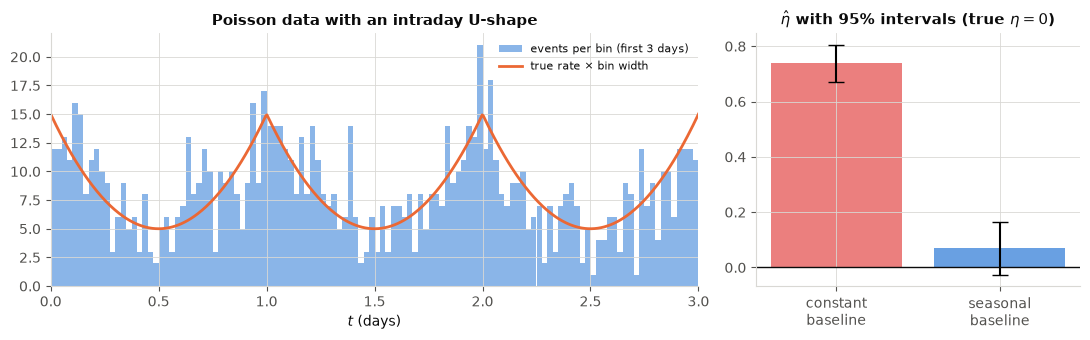

In [1]:

import numpy as np
import matplotlib.pyplot as plt

BLUE, ORANGE, AQUA, YELLOW, VIOLET, RED = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#6250d6", "#e34948"
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#d9d8d4"
plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white",
    "axes.edgecolor": GRID, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False, "axes.titlesize": 11,
    "axes.titleweight": "bold", "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED,
    "text.color": INK, "legend.frameon": False, "font.size": 10})
import math
from scipy import optimize, stats

def negloglik_base(theta, t, base_at_events, base_integral, T):
    """Exponential Hawkes with baseline c * s(t): returns minus log-likelihood and gradient in (c, alpha, beta)."""
    c, a, b = theta
    A = B = 0.0; ll = gc = ga = gb = 0.0
    for i in range(len(t)):
        if i:
            d = t[i] - t[i - 1]; e = math.exp(-b * d)
            B = e * (B + d * (1 + A)); A = e * (1 + A)
        lam = c * base_at_events[i] + a * A
        ll += math.log(lam); gc += base_at_events[i] / lam; ga += A / lam; gb -= a * B / lam
    s = T - t; E = np.exp(-b * s); S1 = np.sum(1 - E); S2 = np.sum(s * E)
    ll -= c * base_integral + a / b * S1
    return -ll, -np.array([gc - base_integral, ga - S1 / b, gb + a / b**2 * S1 - a / b * S2])

def fit(t, base, base_int, T, x0):
    r = optimize.minimize(negloglik_base, x0, args=(t, base, base_int, T), jac=True, method="L-BFGS-B",
                          bounds=[(1e-6, None), (1e-8, None), (1e-2, None)])
    h = 1e-5; H = np.array([(negloglik_base(r.x + h * e, t, base, base_int, T)[1] - negloglik_base(r.x - h * e, t, base, base_int, T)[1]) / (2 * h) for e in np.eye(3)])
    cov = np.linalg.inv((H + H.T) / 2)
    g = np.array([0, 1 / r.x[2], -r.x[1] / r.x[2]**2])          # delta method for eta = alpha / beta
    return r.x, np.sqrt(g @ cov @ g)

rate = lambda t: 200 + 1600 * ((t % 1.0) - 0.5) ** 2
days, M = 20, 600.0
rng = np.random.default_rng(31)
cand = np.sort(rng.uniform(0, days, rng.poisson(M * days)))
t = cand[rng.random(len(cand)) * M <= rate(cand)]
T = float(days); prof = rate(t) / (200 + 1600 / 12)              # profile normalized to mean one
th_c, se_c = fit(t, np.ones(len(t)), T, T, (len(t) / T / 2, 50.0, 100.0))
th_s, se_s = fit(t, prof, T, T, (len(t) / T / 2, 50.0, 100.0))
print(f"n = {len(t)} events (Poisson, true eta = 0)")
print(f"constant baseline: eta_hat = {th_c[1]/th_c[2]:.3f} ± {se_c:.3f}, decay beta_hat = {th_c[2]:.1f} per day")
print(f"seasonal baseline: eta_hat = {th_s[1]/th_s[2]:.3f} ± {se_s:.3f}")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5), gridspec_kw={"width_ratios": [2, 1]})
ax[0].hist(t, bins=np.arange(0, 3.001, 0.025), color=BLUE, alpha=0.55, label="events per bin (first 3 days)")
ax[0].plot(np.linspace(0, 3, 600), rate(np.linspace(0, 3, 600)) * 0.025, color=ORANGE, lw=2, label="true rate × bin width")
ax[0].set(xlim=(0, 3), xlabel="$t$ (days)", title="Poisson data with an intraday U-shape"); ax[0].legend(fontsize=8)
ax[1].bar([0, 1], [th_c[1] / th_c[2], th_s[1] / th_s[2]], yerr=[1.96 * se_c, 1.96 * se_s], color=[RED, BLUE], alpha=0.7, capsize=6)
ax[1].axhline(0, color=INK, lw=1)
ax[1].set(xticks=[0, 1], xticklabels=["constant\nbaseline", "seasonal\nbaseline"], title=r"$\hat\eta$ with 95% intervals (true $\eta = 0$)")
plt.tight_layout(); plt.show()


**Marks.** An exponential Hawkes process where each event carries a log-normal volume $M_i$ and raises the intensity by $\alpha\,\psi(M_i)$, with $\psi(m) = \sqrt{m}/E\sqrt{M}$ (so $E\,\psi(M) = 1$), $\mu = 0.4$, $\alpha = 0.6$, $\beta = 1$; by @prp-marked-branching-ratio $\eta = 0.6$ and $\bar\lambda = 1$. Because the jump sizes are random, the exact simulator only needs the excess intensity to jump by $\alpha\psi(M_i)$. The plot shows the average number of events in the two time units after an event, by decile of its mark: big trades are followed by more activity.

mean rate 1.000  (theory mu/(1 - eta) = 1.000)


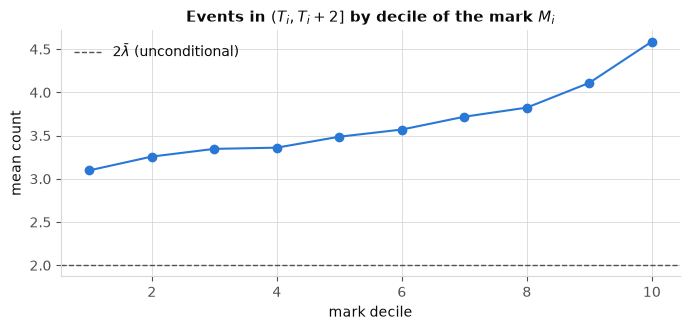

In [2]:

def sim_marked(mu, alpha, beta, T, rng):
    t, ex, ev, mk = 0.0, 0.0, [], []
    Epsi = math.exp(0.125)                                        # E sqrt(M) for M ~ lognormal(0, 1)
    while True:
        e1 = rng.exponential(1 / mu); e2 = math.inf
        if ex > 0:
            D = 1 + beta * math.log(rng.random()) / ex
            if D > 0: e2 = -math.log(D) / beta
        w = min(e1, e2); t += w
        if t > T: return np.array(ev), np.array(mk)
        m = rng.lognormal(0, 1); ex = ex * math.exp(-beta * w) + alpha * math.sqrt(m) / Epsi
        ev.append(t); mk.append(m)

rng = np.random.default_rng(2)
ev, mk = sim_marked(0.4, 0.6, 1.0, 100000.0, rng)
print(f"mean rate {len(ev)/1e5:.3f}  (theory mu/(1 - eta) = {0.4/0.4:.3f})")
after = np.searchsorted(ev, ev + 2.0, side="right") - np.arange(1, len(ev) + 1)
dec = np.digitize(mk, np.quantile(mk, np.linspace(0, 1, 11)[1:-1]))
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.plot(np.arange(1, 11), [after[dec == d].mean() for d in range(10)], "o-", color=BLUE)
ax.axhline(2 * len(ev) / 1e5, color=MUTED, ls="--", lw=1, label=r"$2\bar\lambda$ (unconditional)")
ax.set(title="Events in $(T_i, T_i + 2]$ by decile of the mark $M_i$", xlabel="mark decile", ylabel="mean count"); ax.legend()
plt.tight_layout(); plt.show()


**Inhibition.** A nonlinear Hawkes process with $\Psi(x) = \max(x, 0)$, $\mu = 0.5$ and $h(t) = -e^{-2t}$: every event switches the intensity off for a while. Compared with a self-exciting process with the same baseline and kernel $+e^{-2t}$, the events are more regular, and the Fano factor of counts is below $1$ instead of above.

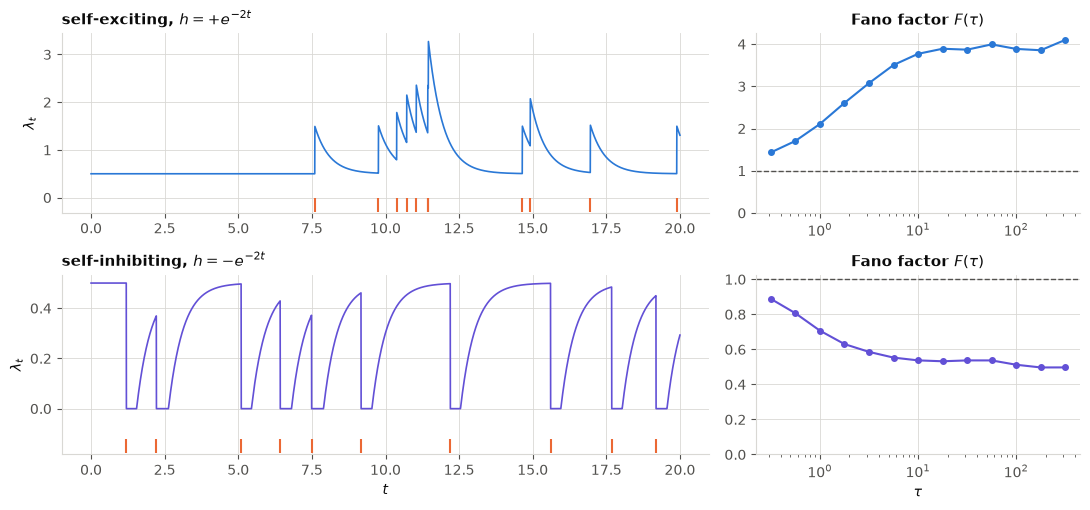

In [3]:

def sim_nonlinear(mu, a, beta, T, rng):
    """lambda = max(mu + sum a e^{-beta (t - T_i)}, 0) by thinning; a < 0 inhibits, a > 0 excites."""
    t, ex, ev = 0.0, 0.0, []
    while True:
        M = max(mu + max(ex, 0.0), 1e-12)                         # bound: positive part can only decay
        w = rng.exponential(1 / M); t += w
        if t > T: return np.array(ev)
        ex *= math.exp(-beta * w)
        if rng.random() * M <= max(mu + ex, 0.0):
            ev.append(t); ex += a

rng = np.random.default_rng(4)
fig, ax = plt.subplots(2, 2, figsize=(11, 5.2), gridspec_kw={"width_ratios": [2, 1]})
g = np.linspace(0, 20, 4000)
for r_, (a, c, nm) in enumerate([(1.0, BLUE, "self-exciting, $h = +e^{-2t}$"), (-1.0, VIOLET, "self-inhibiting, $h = -e^{-2t}$")]):
    e = sim_nonlinear(0.5, a, 2.0, 20.0, rng)
    d = g[:, None] - e[None, :]
    lam = np.maximum(0.5 + (a * np.exp(-2 * np.where(d > 0, d, np.inf))).sum(1), 0)
    ax[r_, 0].plot(g, lam, color=c, lw=1.2); ax[r_, 0].plot(e, np.full(len(e), -0.15), "|", color=ORANGE, ms=10, mew=1.5)
    ax[r_, 0].set_title(nm, loc="left"); ax[r_, 0].set_ylabel(r"$\lambda_t$")
    long = sim_nonlinear(0.5, a, 2.0, 1e5, rng)
    taus = np.logspace(-0.5, 2.5, 13); F = []
    for tau in taus:
        nb = int(1e5 // tau); cnt = np.bincount((long // tau).astype(int), minlength=nb)[:nb]; F.append(cnt.var() / cnt.mean())
    ax[r_, 1].semilogx(taus, F, "o-", color=c, ms=4); ax[r_, 1].axhline(1, color=MUTED, ls="--", lw=1)
    ax[r_, 1].set(title="Fano factor $F(\\tau)$", ylim=(0, None))
ax[1, 0].set_xlabel("$t$"); ax[1, 1].set_xlabel(r"$\tau$")
plt.tight_layout(); plt.show()


**Signature plot.** The price model of @def-hawkes-price-model with $\mu = 0.5$, $\alpha = 0.6$, $\beta = 1$ ($\eta = 0.6$, $\bar\lambda = 1.25$, $\gamma = 1.6$), simulated by multivariate thinning over $T = 10^5$. Left: a stretch of the price path. Right: the realized variance per unit time when sampling every $\tau$, against @thm-signature-plot; it falls from $2\bar\lambda = 2.5$ to $2\bar\lambda/(1+\eta)^2 \approx 0.98$.

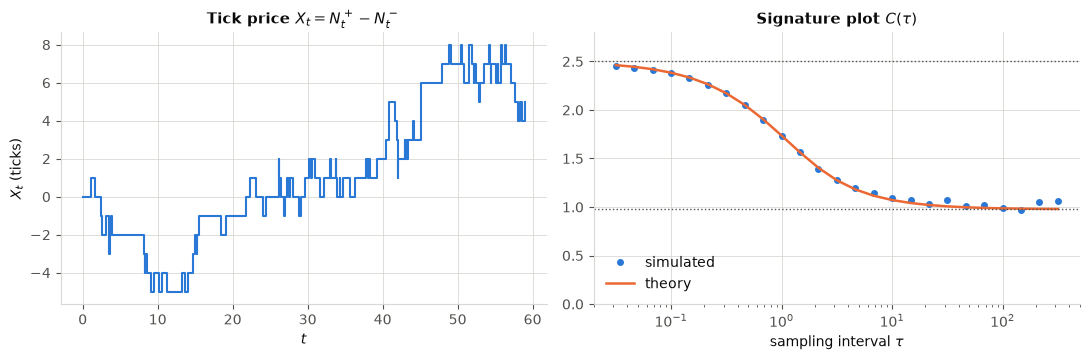

In [4]:

def sim_price(mu, alpha, beta, T, rng, burn=50.0):
    t, ex, times, sgn = -burn, np.zeros(2), [], []            # ex[0]: excess of up-intensity, ex[1]: of down-intensity
    while True:
        M = 2 * mu + ex.sum()
        w = rng.exponential(1 / M); t += w
        if t > T:
            times, sgn = np.array(times), np.array(sgn); k = times > 0; return times[k], sgn[k]
        ex *= math.exp(-beta * w); lam = mu + ex
        u = rng.random() * M
        if u <= lam.sum():
            up = u <= lam[0]
            times.append(t); sgn.append(1 if up else -1)
            ex[1 if up else 0] += alpha                          # an up-move excites down-moves and vice versa

mu_, a_, b_ = 0.5, 0.6, 1.0
T = 1e5
rng = np.random.default_rng(10)
tm, sg = sim_price(mu_, a_, b_, T, rng)
eta = a_ / b_; lbar = mu_ / (1 - eta); gam = a_ + b_
taus = np.logspace(-1.5, 2.5, 25)
emp = []
for tau in taus:
    grid = np.arange(0, T, tau)
    X = np.r_[0, np.cumsum(sg)][np.searchsorted(tm, grid, side="right")]
    emp.append(np.var(np.diff(X)) / tau)
th = 2 * lbar * (1 / (1 + eta) ** 2 + (1 - 1 / (1 + eta) ** 2) * (1 - np.exp(-gam * taus)) / (gam * taus))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.7))
k = tm < 60
ax[0].step(np.r_[0, tm[k]], np.r_[0, np.cumsum(sg[k])], where="post", color=BLUE)
ax[0].set(title="Tick price $X_t = N^+_t - N^-_t$", xlabel="$t$", ylabel="$X_t$ (ticks)")
ax[1].semilogx(taus, emp, "o", color=BLUE, ms=4, label="simulated")
ax[1].semilogx(taus, th, color=ORANGE, lw=1.8, label="theory")
ax[1].axhline(2 * lbar, color=MUTED, ls=":", lw=1); ax[1].axhline(2 * lbar / (1 + eta) ** 2, color=MUTED, ls=":", lw=1)
ax[1].set(title=r"Signature plot $C(\tau)$", xlabel=r"sampling interval $\tau$", ylim=(0, 2.8)); ax[1].legend()
plt.tight_layout(); plt.show()